**Estado: Cerrado exploratorio; resultado negativo del protocolo.** Cierre: 2026-10-26. Conclusiones y límites al final del notebook. [Tabla global de benchmarks](../../BENCHMARKS.md).


# Onda multiescala: PINN base frente a PCA espacial

Pregunta: ¿PCA espacial al 99% reduce tiempo y mantiene precisión cuando la solución contiene frecuencias separadas?

Se usa $u_{tt}-4u_{xx}=0$ en $x,t\in[0,1]$, con $u(0,t)=u(1,t)=0$ y $u_t(x,0)=0$. La solución de dos frecuencias es

$$u(x,t)=\sin(\pi x)\cos(2\pi t)+0.5\sin(4\pi x)\cos(8\pi t).$$

El segundo caso añade $0.25\sin(9\pi x)\cos(18\pi t)$.

Fuente del problema: Datar et al. (2026), *Fast Training of Accurate Physics-Informed Neural Networks without Gradient Descent*, apéndice C.3, ecuaciones 27a–27h, [arXiv:2405.20836v3](https://arxiv.org/abs/2405.20836v3). El protocolo supervisado es el de este repositorio; no se reproduce el entrenamiento de Frozen-PINN ni se comparan sus tiempos publicados.

## Protocolo fijado antes de entrenar

- Diez semillas y 2000 pasos para cada caso y modelo; mismos lotes, particiones, condiciones iniciales y puntos de colocación dentro de cada pareja.
- PCA centrado se ajusta solo a snapshots de tiempos de entrenamiento. La red reducida predice coeficientes temporales sobre esa base espacial fija, en su escala original y sin estandarización adicional: esta variante difiere del PCA de coordenadas usado en dimensión alta.
- Ambas redes tienen tres capas ocultas tanh, parámetros emparejados dentro de 5% y la misma tasa de aprendizaje. Una misma semilla no implica pesos idénticos entre arquitecturas diferentes.
- La pérdida suma MSE de datos, residuo PDE, desplazamiento inicial, velocidad inicial cero y fronteras. Los cinco pesos se fijan en 1 para ambos modelos. Las muestras supervisadas provienen de los mismos snapshots de entrenamiento.
- JAX calcula las segundas derivadas en ambos modelos. La media y los modos PCA se interpolan con splines cúbicos C2, preparados una vez fuera del entrenamiento y evaluados por JAX.
- Pipeline = ajuste PCA + preparación de splines + entrenamiento + validación periódica. Compilación, preparación de lotes y evaluación final se registran fuera de ese tiempo. Se alterna el orden base/PCA entre semillas y se compila una vez por arquitectura durante el proceso.
- Prueba usa los mismos 20 tiempos reservados por pareja. El residuo se autodiferencia sobre los mismos 512 puntos de prueba. PCA no se ajusta con validación o prueba.

Los outputs se generan desde los artefactos guardados. No es necesario entrenar para abrir este notebook.

In [ ]:
from pathlib import Path
import json, sys
from IPython.display import display, HTML, SVG
ROOT = Path.cwd()
while not (ROOT / 'pyproject.toml').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from pinn_pca.wave_report import metrics_table, pca_table, paired_table, loss_table
RUN_DIR = ROOT / 'results/wave/base_vs_pca/two_and_three_frequencies_10_seeds_2k_v1'
RESULT = json.loads((RUN_DIR / 'summary.json').read_text(encoding='utf-8'))

## Métricas finales

Media ± desviación estándar entre semillas. Un residuo bajo debe interpretarse junto con el error de solución y las condiciones iniciales.

In [ ]:
display(HTML(metrics_table(RESULT)))

Caso,Modelo,Error relativo L2 (media ± DE),Residuo RMS de onda (AD) (media ± DE),Pipeline (s) (media ± DE)
two_frequencies,PINN base,0.5378 ± 0.0386,0.07007 ± 0.0189,8.94 ± 0.434
two_frequencies,PCA espacial 99%,1 ± 0.000478,0.04215 ± 0.0179,7.19 ± 0.328
three_frequencies,PINN base,0.5722 ± 0.0374,0.07731 ± 0.0258,9.607 ± 0.811
three_frequencies,PCA espacial 99%,1 ± 0.000463,0.3158 ± 0.443,7.951 ± 0.646


## Capacidad de representación

La proyección oráculo usa los coeficientes calculados desde las etiquetas de prueba exclusivamente como diagnóstico. No es una predicción entrenada ni interviene en la selección de k. Un error de proyección pequeño junto a un error grande de red indica que retener los modos no basta para aprender sus coeficientes temporales. Esta cota mide valores de u en la malla de prueba; no garantiza igual precisión de las derivadas de los splines.

In [ ]:
display(HTML(pca_table(RESULT)))

Caso,k,Varianza media retenida,Error L2 proyección test (oráculo),Parámetros PCA
two_frequencies,[2],100.000000%,2.55e-08,[8578]
three_frequencies,[3],100.000000%,2.62e-08,[8643]


## Diferencias pareadas

PCA − base; menor es mejor para las tres métricas. Los intervalos bootstrap remuestrean diferencias dentro de las mismas semillas. Este piloto es exploratorio, sin selección posterior de k con prueba.

In [ ]:
display(HTML(paired_table(RESULT)))

Caso,Métrica,Δ media PCA − base,IC bootstrap 95%,PCA menor
two_frequencies,Error relativo L2,0.4621,"[0.4405, 0.4844]",0/10
two_frequencies,Residuo RMS de onda (AD),-0.02792,"[-0.0431, -0.01387]",9/10
two_frequencies,Pipeline (s),-1.75,"[-2.202, -1.439]",10/10
three_frequencies,Error relativo L2,0.4279,"[0.4066, 0.4496]",0/10
three_frequencies,Residuo RMS de onda (AD),0.2385,"[0.005789, 0.5295]",5/10
three_frequencies,Pipeline (s),-1.656,"[-1.941, -1.308]",10/10


## Componentes de la pérdida

Medias en el último minibatch después de la última actualización. Una solución pequeña puede satisfacer aproximadamente la ecuación homogénea mientras falla en desplazamiento inicial o datos. Se registra por separado la condición de velocidad inicial.

In [ ]:
display(HTML(loss_table(RESULT)))

Caso,Modelo,MSE data,MSE pde,MSE initial_u,MSE initial_ut,MSE boundary
two_frequencies,PINN base,0.08216,0.004597,0.08848,0.001597,0.02664
two_frequencies,PCA espacial 99%,0.3136,0.001973,0.603,1.351e-05,3.204e-21
three_frequencies,PINN base,0.09979,0.006411,0.1127,0.002018,0.02615
three_frequencies,PCA espacial 99%,0.3332,0.271,0.6287,1.619e-05,1.776e-21


## Figuras

Las curvas resumen validación entre semillas. El error por armónico compara los coeficientes obtenidos por proyección de las predicciones en los modos seno con sus valores analíticos en prueba. Las imágenes de campo usan la primera semilla fijada antes de entrenar, no la mejor corrida; incluyen todos los tiempos solo para visualizar el resultado final.

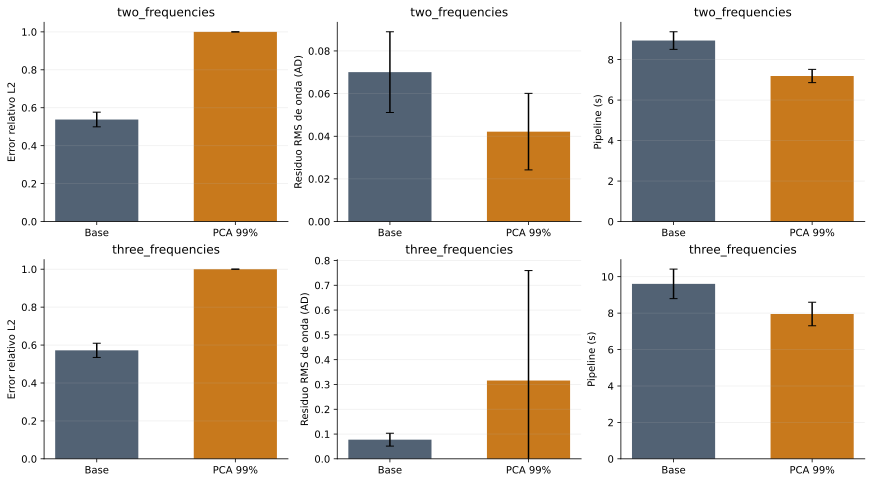

In [ ]:
display(SVG(filename=str(RUN_DIR / 'comparison.svg')))

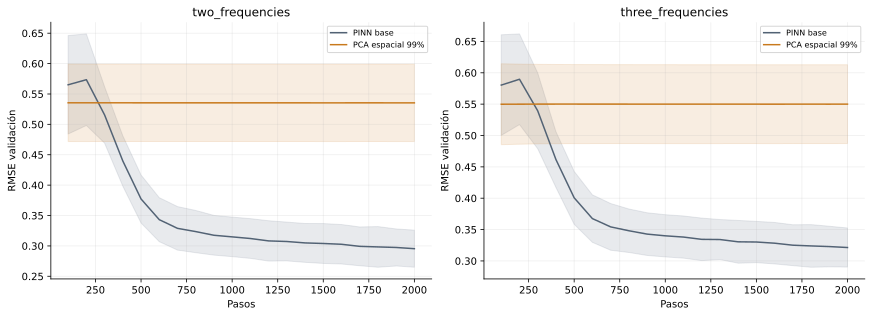

In [ ]:
display(SVG(filename=str(RUN_DIR / 'validation_vs_steps.svg')))

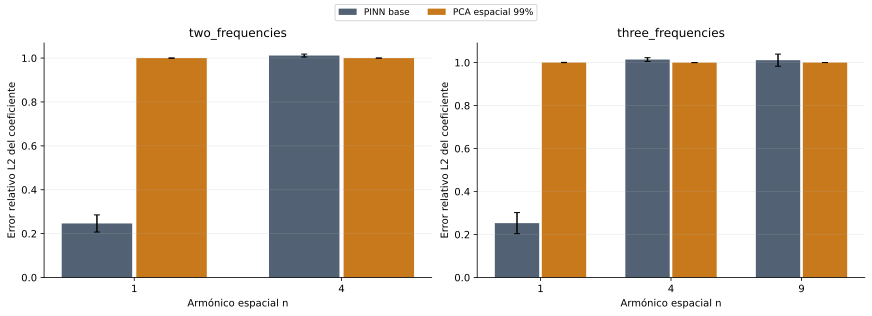

In [ ]:
display(SVG(filename=str(RUN_DIR / 'frequency_errors.svg')))

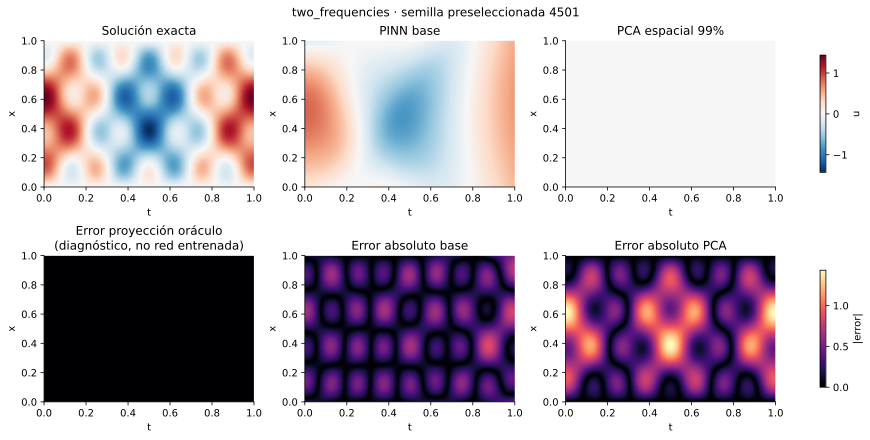

In [ ]:
display(SVG(filename=str(RUN_DIR / 'fields_two_frequencies.svg')))

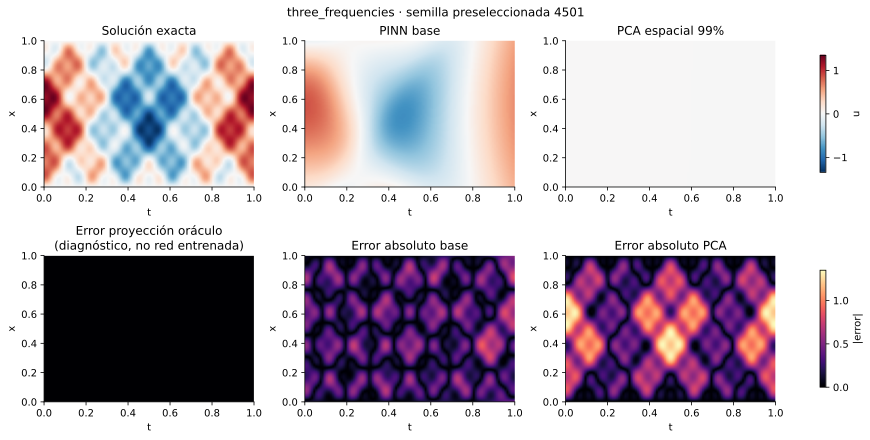

In [ ]:
display(SVG(filename=str(RUN_DIR / 'fields_three_frequencies.svg')))

## Lectura del piloto

- **two_frequencies**: Error relativo L2: Δ media 0.4621, PCA menor en 0/10 semillas; Residuo RMS de onda (AD): Δ media -0.02792, PCA menor en 9/10 semillas; Pipeline (s): Δ media -1.75, PCA menor en 10/10 semillas.
- **three_frequencies**: Error relativo L2: Δ media 0.4279, PCA menor en 0/10 semillas; Residuo RMS de onda (AD): Δ media 0.2385, PCA menor en 5/10 semillas; Pipeline (s): Δ media -1.656, PCA menor en 10/10 semillas.

La evidencia queda limitada a Adam, estos pesos de pérdida y 2000 pasos. Un fallo de este piloto no establece que la arquitectura sea incapaz de resolver la ecuación; una mejora de tiempo con mayor error tampoco demuestra eficiencia a calidad equivalente. Los errores por frecuencia y la proyección oráculo permiten decidir qué dificultad conviene estudiar después. No se reajustan componentes ni pérdidas con el conjunto de prueba.

Regenerar entrenamiento: `python scripts/run_wave_multiscale.py --config configs/wave_multiscale_pilot.json`. Regenerar solo figuras y notebook: añadir `--report-only`; esta opción no importa JAX. CSV, configuración, resumen y figuras SVG/PNG se conservan en la carpeta de resultados.

## Cierre del benchmark de onda multiescala

**Estado: cerrado como estudio exploratorio con resultado negativo para la configuración evaluada.** Fecha de cierre: 26 de octubre de 2026.

### Alcance y evidencia conservada

Se evaluaron las soluciones de dos y tres frecuencias de `u_tt − 4u_xx = 0`, con diez semillas por caso, Adam, 2000 pasos y cinco términos de pérdida de peso uniforme. PCA espacial al 99% retuvo dos y tres componentes, respectivamente. El piloto ejecutó 40 ajustes y el diagnóstico ejecutó 60; 40 de estos últimos repiten los modelos del piloto. Estos ajustes no constituyen 100 réplicas independientes: se conservaron las mismas diez semillas en cada caso.

La ronda final comparó PINN base, PCA original y PCA con coeficientes estandarizados, manteniendo muestras, particiones, k, arquitectura y pérdida. El escalador se ajustó solo con entrenamiento. La transformación inversa de la última capa conservó el campo físico inicial, con diferencia máxima de 2.98e-8. Los 800 checkpoints de base y PCA original reprodujeron exactamente el piloto.

### Conclusiones respaldadas

- **Representación de los datos:** la proyección PCA en la malla de prueba conserva la solución con error L2 cercano a 2.6e-8. El truncamiento espacial no explica por sí solo el error de la red entrenada en estos casos.
- **Entrenamiento:** el L2 medio final de PCA original/estandarizada es 0.999951/0.999885 con dos frecuencias y 1.000070/1.000039 con tres. Las predicciones siguen próximas a cero. Estandarizar los coeficientes por sí solo no produce una mejora práctica.
- **Referencia base:** sus errores L2 medios son 0.537803 y 0.572163. También conserva un error considerable; este presupuesto no establece una solución de alta precisión para ninguna de las dos arquitecturas.
- **Física de la representación:** los controles con coeficientes exactos pasan los criterios prácticos fijados antes de evaluar validación. El spline conserva residuos RMS medios de validación de 0.0161 y 0.1881; la precisión de los valores de u no se traslada automáticamente a sus derivadas. La reconstrucción oráculo puede alcanzar una pérdida mucho menor que la solución nula.
- **Tiempo:** un menor tiempo de pipeline con error de solución mayor no respalda una aceleración a calidad equivalente. La hipótesis de reducción útil del tiempo no queda respaldada por este benchmark.

### Límites de la interpretación

El predominio inicial del gradiente PDE dentro de cada parametrización PCA es compatible con un desequilibrio de optimización. Las normas dependen de las coordenadas de parámetros y esta observación no demuestra una causa única. La pérdida, el optimizador, el presupuesto, la red temporal y la interpolación siguen formando parte del protocolo evaluado.

El resultado negativo corresponde a esta combinación de PCA y PINN, a estos datos y al presupuesto ensayado. No demuestra una imposibilidad general de PCA, ni que la pérdida de información sea la causa del fallo. Los coeficientes exactos se utilizaron exclusivamente como diagnóstico, no como una red entrenada competidora.

### Decisión de cierre

Se conserva el resultado negativo y se detiene la búsqueda de ajustes dentro de este benchmark. Una investigación futura con nuevas pérdidas, optimizadores o presupuestos debe registrarse como un estudio separado, con criterios fijados antes de evaluar sus resultados. La tabla global conserva el estado y las fuentes de esta conclusión.

Corridas de referencia: `two_and_three_frequencies_10_seeds_2k_v1` y `diagnostic_standardized_coefficients_10_seeds_2k_v1`.
